# Halvorsen single test trajectory

This notebook creates one `halvorsen_a_chaotic_to_periodic` test trajectory with adjustable parameter drift and evaluates it directly in memory.

Edit the parameters in the next cell, rerun the simulation cell, then run the DynaMix evaluation cells. Saving `test.npy` is optional and disabled by default.

In [8]:
from __future__ import annotations

import inspect
import json
import math
import sys
from dataclasses import asdict, replace
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp
from scipy.ndimage import gaussian_filter1d
import torch

try:
    from safetensors.torch import load_file as load_safetensors
except ImportError:
    load_safetensors = None

from generate_dynamic_regime_trajectories import (
    default_regimes,
    RHS,
    normalize_phi,
    observe_state,
    standardize_trajectories,
)

MASTER = Path(
    r"C:\Users\koray\OneDrive\Dokumente\Studium\Master\Heidelberg\Master_Thesis"
)
DYNAMIX_REPO = MASTER / "DynaMix-python-b-tipping"
DYNAMIX_RUN = (
    DYNAMIX_REPO / "results" / "single_halvorsen_constparams" / "14to209_noisy-with-phi"
    # / "single_halvorsen_linearphi"
    # / "14to209_10ksteps"
    # / "after_0_with_phi"
    # / "whole_range_with_phi"
)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

Device: cpu


In [9]:
# Drift experiment knobs
a_start = 1.4
a_end = 2.09
boundary = 1.75

# Total trajectory length and forecast split.
context_steps = 2000
total_steps = 12000
forecast_steps = total_steps - context_steps

# a(t) is constant at a_start before drift_start_step, linear until drift_end_step,
# then constant at a_end. Use 0..total_steps for a linear drift over the full trajectory.
drift_start_step = 0
drift_end_step = 12000
dt = 0.01

# One trajectory by default. Increase this if you want a small batch in test.npy.
n_trajectories = 1
seed = 8
burn_in_steps = 5000
rtol = 1e-6
atol = 1e-8
max_step_multiplier = 5.0

SAVE_OUTPUT = False
OUTPUT_DIR = Path("single_halvorsen_quick_test")
TRAJECTORY_IDS = list(range(n_trajectories))

if not (0 <= drift_start_step < drift_end_step <= total_steps):
    raise ValueError("Need 0 <= drift_start_step < drift_end_step <= total_steps")

print("Physical duration:", (total_steps - 1) * dt)
print("Context steps:", context_steps)
print("Forecast steps:", forecast_steps)
print("Drift window steps:", drift_start_step, "to", drift_end_step)
print(
    "Parameter drift per drift step:",
    (a_end - a_start) / max(drift_end_step - drift_start_step - 1, 1),
)
print("Save output:", SAVE_OUTPUT)
if SAVE_OUTPUT:
    print("Output dir:", OUTPUT_DIR.resolve())

Physical duration: 119.99000000000001
Context steps: 2000
Forecast steps: 10000
Drift window steps: 0 to 12000
Parameter drift per drift step: 5.750479206600549e-05
Save output: False


In [10]:
# 1. Zufälliger Anfangszustand
# 2. Burn-in bei konstantem a_start
# 3. Aufnahme der Testtrajektorie beginnt
# 4. a bleibt bis drift_start_step konstant, driftet dann linear bis drift_end_step,
#    und bleibt danach bei a_end.
# 5. DynaMix bekommt die ersten context_steps Punkte und forecastet den Rest.


def get_halvorsen_regime():
    regimes = {regime.name: regime for regime in default_regimes()}
    base = regimes["halvorsen_a_chaotic_to_periodic"]
    return replace(base, start=a_start, end=a_end, boundary=boundary)


def piecewise_linear_parameter_by_step(step: np.ndarray | float) -> np.ndarray | float:
    s = (np.asarray(step, dtype=np.float64) - drift_start_step) / max(
        drift_end_step - drift_start_step - 1, 1
    )
    s = np.clip(s, 0.0, 1.0)
    value = a_start + (a_end - a_start) * s
    return float(value) if np.ndim(value) == 0 else value


def simulate_halvorsen_piecewise_drift(regime):
    t_eval = np.arange(total_steps, dtype=np.float64) * dt
    t_end = float(t_eval[-1])
    rhs = RHS[regime.rhs_key]
    phi_raw = piecewise_linear_parameter_by_step(np.arange(total_steps))[
        :, None
    ].astype(np.float32)
    phi = normalize_phi(phi_raw, a_start, a_end, boundary).astype(np.float32)
    trajectories = np.empty((n_trajectories, total_steps, 3), dtype=np.float32)

    def parameter_at_time(t: float) -> float:
        return piecewise_linear_parameter_by_step(t / dt)

    def ode_main(t: float, x: np.ndarray) -> np.ndarray:
        dx = rhs(t, x, parameter_at_time(t), **regime.params)
        return np.clip(dx, -1e4, 1e4)

    def ode_burn_in(t: float, x: np.ndarray) -> np.ndarray:
        dx = rhs(t, x, a_start, **regime.params)
        return np.clip(dx, -1e4, 1e4)

    for k in range(n_trajectories):
        x0 = rng.normal(
            loc=np.array(regime.init_center), scale=np.array(regime.init_scale)
        )

        if burn_in_steps > 0:
            burn = solve_ivp(
                ode_burn_in,
                (0.0, burn_in_steps * dt),
                x0,
                method="DOP853",
                rtol=rtol,
                atol=atol,
                max_step=dt * max_step_multiplier,
            )
            if not burn.success:
                raise RuntimeError(f"Burn-in failed for {regime.name}: {burn.message}")
            x0 = burn.y[:, -1]

        sol = solve_ivp(
            ode_main,
            (0.0, t_end),
            x0,
            t_eval=t_eval,
            method="DOP853",
            rtol=rtol,
            atol=atol,
            max_step=dt * max_step_multiplier,
        )
        if not sol.success or sol.y.shape[1] != total_steps:
            raise RuntimeError(f"Integration failed for {regime.name}: {sol.message}")

        traj = observe_state(sol.y.T, regime.observation)
        if not np.all(np.isfinite(traj)):
            raise RuntimeError(f"Non-finite trajectory generated for {regime.name}")
        trajectories[k] = traj.astype(np.float32)

    return trajectories, phi, phi_raw


rng = np.random.default_rng(seed)
regime = get_halvorsen_regime()

trajectories, phi, phi_raw = simulate_halvorsen_piecewise_drift(regime)

# Match generate_dynamic_regime_trajectories.py: standardize per simulated series.
trajectories_std, mean, std = standardize_trajectories(trajectories)
test = trajectories_std.transpose(1, 0, 2).astype(np.float32)
test_phi = (
    np.repeat(phi[None, :, :], n_trajectories, axis=0)
    .transpose(1, 0, 2)
    .astype(np.float32)
)
test_phi_raw = (
    np.repeat(phi_raw[None, :, :], n_trajectories, axis=0)
    .transpose(1, 0, 2)
    .astype(np.float32)
)

metadata = {
    "description": "Single Halvorsen a chaotic-to-periodic test trajectory for DynaMix evaluation.",
    "regime": asdict(regime),
    "context_steps": context_steps,
    "forecast_steps": forecast_steps,
    "total_steps": total_steps,
    "dt": dt,
    "n_trajectories": n_trajectories,
    "seed": seed,
    "burn_in_steps": burn_in_steps,
    "drift_start_step": drift_start_step,
    "drift_end_step": drift_end_step,
    "shapes": {
        "test": list(test.shape),
        "test_phi": list(test_phi.shape),
        "test_phi_raw": list(test_phi_raw.shape),
    },
    "phi_convention": "phi = (a - boundary) / max(abs(start-boundary), abs(end-boundary)).",
}
if SAVE_OUTPUT:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    np.save(OUTPUT_DIR / "test.npy", test)
    np.save(OUTPUT_DIR / "test_phi.npy", test_phi)
    np.save(OUTPUT_DIR / "test_phi_raw.npy", test_phi_raw)
    np.save(OUTPUT_DIR / "halvorsen_a_chaotic_to_periodic_mean.npy", mean)
    np.save(OUTPUT_DIR / "halvorsen_a_chaotic_to_periodic_std.npy", std)
    (OUTPUT_DIR / "metadata.json").write_text(
        json.dumps(metadata, indent=2), encoding="utf-8"
    )
    print("Saved", OUTPUT_DIR.resolve())
else:
    print("Generated in memory only. Set SAVE_OUTPUT = True if you want files.")

print("test.npy:", test.shape)
print("test_phi.npy:", test_phi.shape)
print(
    "context a range:",
    float(test_phi_raw[0, 0, 0]),
    "to",
    float(test_phi_raw[context_steps - 1, 0, 0]),
)
print(
    "context phi range:",
    float(test_phi[0, 0, 0]),
    "to",
    float(test_phi[context_steps - 1, 0, 0]),
)
print(f"context slice: test[0:{context_steps}]")
print(f"target slice:  test[{context_steps}:{context_steps + forecast_steps}]")

Generated in memory only. Set SAVE_OUTPUT = True if you want files.
test.npy: (12000, 1, 3)
test_phi.npy: (12000, 1, 1)
context a range: 1.399999976158142 to 1.5149520635604858
context phi range: -1.0000001192092896 to -0.6715655326843262
context slice: test[0:2000]
target slice:  test[2000:12000]


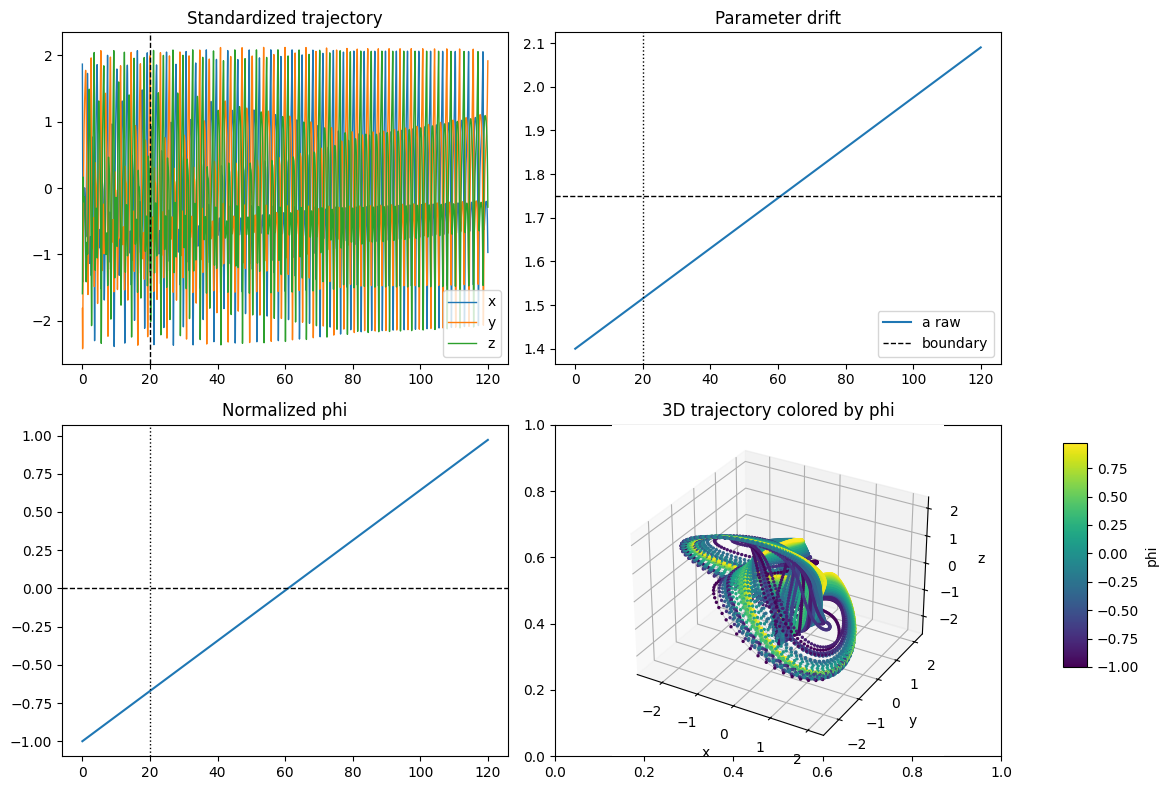

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
t = np.arange(total_steps) * dt

for dim, label in enumerate(["x", "y", "z"]):
    axes[0, 0].plot(t, test[:, 0, dim], lw=1.0, label=label)
axes[0, 0].axvline(context_steps * dt, color="black", ls="--", lw=1.0)
axes[0, 0].set_title("Standardized trajectory")
axes[0, 0].legend()

axes[0, 1].plot(t, test_phi_raw[:, 0, 0], lw=1.5, label="a raw")
axes[0, 1].axhline(boundary, color="black", ls="--", lw=1.0, label="boundary")
axes[0, 1].axvline(context_steps * dt, color="black", ls=":", lw=1.0)
axes[0, 1].set_title("Parameter drift")
axes[0, 1].legend()

axes[1, 0].plot(t, test_phi[:, 0, 0], lw=1.5)
axes[1, 0].axhline(0.0, color="black", ls="--", lw=1.0)
axes[1, 0].axvline(context_steps * dt, color="black", ls=":", lw=1.0)
axes[1, 0].set_title("Normalized phi")

ax3d = fig.add_subplot(2, 2, 4, projection="3d")
phi_values = test_phi[:, 0, 0]
ax3d.plot(test[:, 0, 0], test[:, 0, 1], test[:, 0, 2], color="0.75", lw=0.5)
sc = ax3d.scatter(
    test[:, 0, 0],
    test[:, 0, 1],
    test[:, 0, 2],
    c=phi_values,
    cmap="viridis",
    s=2,
    depthshade=False,
)
ax3d.set_title("3D trajectory colored by phi")
ax3d.set_xlabel("x")
ax3d.set_ylabel("y")
ax3d.set_zlabel("z")
plt.tight_layout(rect=[0.0, 0.0, 0.86, 1.0])
cax = fig.add_axes([0.89, 0.16, 0.02, 0.28])
fig.colorbar(sc, cax=cax, label="phi")

## Normal DynaMix evaluation

The cells below load `MASTER / "DynaMix-python" / "results" / "full-model"` and forecast from the first `context_steps` points using the in-memory `test` array.

In [12]:
def purge_dynamix_modules() -> None:
    for name in list(sys.modules):
        if name == "dynamix" or name.startswith("dynamix."):
            del sys.modules[name]


def import_from_repo(repo: Path):
    purge_dynamix_modules()
    src = str(repo / "src")
    sys.path = [
        p
        for p in sys.path
        if not (
            p.endswith(r"DynaMix-python\src")
            or p.endswith(r"DynaMix-python-b-tipping\src")
        )
    ]
    sys.path.insert(0, src)

    from dynamix.model.dynamix import DynaMix
    from dynamix.model.forecaster import DynaMixForecaster

    return DynaMix, DynaMixForecaster


def find_checkpoint(run_dir: Path, checkpoint_name: str = "final_model") -> Path:
    checkpoint_dir = run_dir / "checkpoints"
    for suffix in (".safetensors", ".pt"):
        candidate = checkpoint_dir / f"{checkpoint_name}{suffix}"
        if candidate.exists():
            return candidate
    raise FileNotFoundError(
        f"No {checkpoint_name}.safetensors/.pt found in {checkpoint_dir}"
    )


def load_state_dict(checkpoint_path: Path, device: str) -> dict[str, torch.Tensor]:
    if checkpoint_path.suffix == ".safetensors":
        if load_safetensors is None:
            raise ImportError("Install safetensors to load .safetensors checkpoints")
        return load_safetensors(str(checkpoint_path), device=device)
    return torch.load(checkpoint_path, map_location=device)


def infer_architecture(
    config: dict[str, Any], state: dict[str, torch.Tensor]
) -> dict[str, Any]:
    n_obs, latent_dim = map(int, state["B"].shape)
    expert_indices = {
        int(key.split(".")[1])
        for key in state
        if key.startswith("experts.") and key.split(".")[1].isdigit()
    }
    return {
        "M": latent_dim,
        "N": n_obs,
        "Experts": len(expert_indices) or int(config["experts"]),
        "P": int(config.get("pwl_units", 2)),
        "hidden_dim": int(config.get("hidden_dim", 50)),
        "expert_type": config.get("expert_type", "almost_linear_rnn"),
        "probabilistic_expert": bool(config.get("probabilistic_expert", False)),
        "phi_dim": int(config.get("phi_dim", 0)),
    }


def calc_histogram(
    x: torch.Tensor, n_bins: int, min_: torch.Tensor, max_: torch.Tensor
) -> torch.Tensor:
    dim_x = x.shape[1]
    width = torch.clamp(max_ - min_, min=1e-8)
    coordinates = (n_bins * (x - min_) / width).long()
    inlier = ((coordinates > 0) & (coordinates < n_bins)).all(1)
    coordinates = coordinates[inlier]
    size_ = tuple(n_bins for _ in range(dim_x))
    indices = torch.ones(coordinates.shape[0], device=coordinates.device)
    return torch.sparse_coo_tensor(coordinates.t(), indices, size=size_).to_dense()


def normalize_to_pdf_with_laplace_smoothing(
    histogram: torch.Tensor, n_bins: int, smoothing_alpha: float = 10e-6
) -> torch.Tensor | None:
    if histogram.sum() == 0:
        return None
    dim_x = len(histogram.shape)
    return (histogram + smoothing_alpha) / (
        histogram.sum() + smoothing_alpha * n_bins**dim_x
    )


def kullback_leibler_divergence(
    p1: torch.Tensor | None, p2: torch.Tensor | None
) -> float:
    if p1 is None or p2 is None:
        return float("nan")
    return (p1 * torch.log(p1 / p2)).sum().item()


def geometrical_misalignment(
    x_gen: torch.Tensor, x_true: torch.Tensor, n_bins: int = 30
) -> float:
    min_, max_ = x_true.min(0).values, x_true.max(0).values
    hist_gen = calc_histogram(x_gen, n_bins=n_bins, min_=min_, max_=max_)
    hist_true = calc_histogram(x_true, n_bins=n_bins, min_=min_, max_=max_)
    p_gen = normalize_to_pdf_with_laplace_smoothing(hist_gen, n_bins=n_bins)
    p_true = normalize_to_pdf_with_laplace_smoothing(hist_true, n_bins=n_bins)
    return kullback_leibler_divergence(p_true, p_gen)


def compute_and_smooth_power_spectrum(x: np.ndarray, smoothing: int) -> np.ndarray:
    std = x.std()
    x_ = (x - x.mean()) / (std if std > 1e-8 else 1.0)
    ps = np.abs(np.fft.rfft(x_)) ** 2 * 2 / len(x_)
    ps_smoothed = gaussian_filter1d(ps, smoothing)
    total = ps_smoothed.sum()
    return ps_smoothed / total if total > 0 else ps_smoothed


def hellinger_distance(p: np.ndarray, q: np.ndarray) -> float:
    return float(np.sqrt(1 - np.sum(np.sqrt(p * q))))


def temporal_misalignment(
    x_gen: np.ndarray, x_true: np.ndarray, smoothing: int = 20
) -> float:
    dists = []
    for i in range(x_true.shape[1]):
        ps_true = compute_and_smooth_power_spectrum(x_true[:, i], smoothing)
        ps_gen = compute_and_smooth_power_spectrum(x_gen[:, i], smoothing)
        dists.append(hellinger_distance(ps_true, ps_gen))
    return float(np.mean(dists))


def mase_like_training(
    x_true: torch.Tensor, x_gen: torch.Tensor, steps: int = 10, naive_lag: int = 1
) -> float:
    steps = min(steps, x_true.shape[0])
    mase = torch.mean(torch.abs(x_true[:steps] - x_gen[:steps]), dim=0)
    naive_mase = torch.mean(torch.abs(x_gen[naive_lag:] - x_gen[:-naive_lag]), dim=0)
    return (mase / (naive_mase + 1e-8)).mean().item()


def dynamix_qualitative_metrics(
    pred: torch.Tensor,
    truth: torch.Tensor,
    n_bins: int = 30,
    ps_smoothing: int = 20,
    mase_steps: int = 10,
) -> dict[str, float]:
    pred_cpu = pred.detach().cpu()
    truth_cpu = truth.detach().cpu()
    dstsp_values = []
    dh_values = []
    mase_values = []
    for eval_id in range(truth_cpu.shape[1]):
        pred_i = pred_cpu[:, eval_id, :]
        truth_i = truth_cpu[:, eval_id, :]
        dstsp_values.append(geometrical_misalignment(pred_i, truth_i, n_bins=n_bins))
        dh_values.append(
            temporal_misalignment(
                pred_i.numpy(), truth_i.numpy(), smoothing=ps_smoothing
            )
        )
        mase_values.append(mase_like_training(truth_i, pred_i, steps=mase_steps))
    return {
        "dstsp": float(torch.nanmedian(torch.tensor(dstsp_values)).item()),
        "dh": float(torch.nanmedian(torch.tensor(dh_values)).item()),
        "mase": float(torch.nanmedian(torch.tensor(mase_values)).item()),
    }


def load_normal_dynamix(
    repo: Path = DYNAMIX_REPO, run_dir: Path = DYNAMIX_RUN, device: str = DEVICE
):
    DynaMix, DynaMixForecaster = import_from_repo(repo)
    config = json.loads((run_dir / "config.json").read_text())
    checkpoint_path = find_checkpoint(run_dir)
    state = load_state_dict(checkpoint_path, device)
    arch = infer_architecture(config, state)

    kwargs = {
        "M": arch["M"],
        "N": arch["N"],
        "Experts": arch["Experts"],
        "P": arch["P"],
        "hidden_dim": arch["hidden_dim"],
        "expert_type": arch["expert_type"],
        "probabilistic_expert": arch["probabilistic_expert"],
    }
    if "phi_dim" in inspect.signature(DynaMix).parameters:
        kwargs["phi_dim"] = arch["phi_dim"]

    model = DynaMix(**kwargs).to(device)
    model.load_state_dict(state)
    model.eval()
    return model, DynaMixForecaster(model), config, arch, checkpoint_path


@torch.no_grad()
def forecast_normal_dynamix(
    test_arr: np.ndarray = test, phi_arr: np.ndarray = test_phi
):
    model, forecaster, config, arch, checkpoint_path = load_normal_dynamix()
    test_arr = test_arr.astype(np.float32)
    context = torch.tensor(test_arr[:context_steps, TRAJECTORY_IDS, :], device=DEVICE)
    truth = torch.tensor(
        test_arr[context_steps : context_steps + forecast_steps, TRAJECTORY_IDS, :],
        device=DEVICE,
    )
    phi_future = None
    if arch["phi_dim"] > 0:
        phi_future = torch.tensor(
            phi_arr[context_steps : context_steps + forecast_steps, TRAJECTORY_IDS, :],
            device=DEVICE,
        )
    pred = forecaster.forecast(context, forecast_steps, phi_future=phi_future)
    err = pred - truth
    mse = torch.mean(err**2).item()
    rmse = math.sqrt(mse)
    mae = torch.mean(torch.abs(err)).item()
    scale = torch.std(truth).item()
    nrmse = rmse / scale if scale > 0 else float("nan")
    qualitative = dynamix_qualitative_metrics(pred, truth)
    return {
        "pred": pred.detach().cpu().numpy(),
        "truth": truth.detach().cpu().numpy(),
        "context": context.detach().cpu().numpy(),
        "metrics": {
            "mse": mse,
            "rmse": rmse,
            "mae": mae,
            "nrmse": nrmse,
            **qualitative,
        },
        "arch": arch,
        "checkpoint": checkpoint_path,
    }

In [13]:
result = forecast_normal_dynamix(test)
print("Checkpoint:", result["checkpoint"])
print("Architecture:", result["arch"])
print("Metrics:", result["metrics"])

Checkpoint: C:\Users\koray\OneDrive\Dokumente\Studium\Master\Heidelberg\Master_Thesis\DynaMix-python-b-tipping\results\single_halvorsen_constparams\14to209_noisy-with-phi\checkpoints\final_model.safetensors
Architecture: {'M': 30, 'N': 3, 'Experts': 10, 'P': 2, 'hidden_dim': 50, 'expert_type': 'almost_linear_rnn', 'probabilistic_expert': False, 'phi_dim': 1}
Metrics: {'mse': 1.9368103742599487, 'rmse': 1.3916933477817406, 'mae': 1.093462347984314, 'nrmse': 1.3963172731733529, 'dstsp': 5.925647735595703, 'dh': 0.0217501949518919, 'mase': 0.3707242012023926}


C:\Users\koray\AppData\Local\Temp\ipykernel_14784\1919498763.py:76: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\Context.cpp:767.)
  return torch.sparse_coo_tensor(coordinates.t(), indices, size=size_).to_dense()


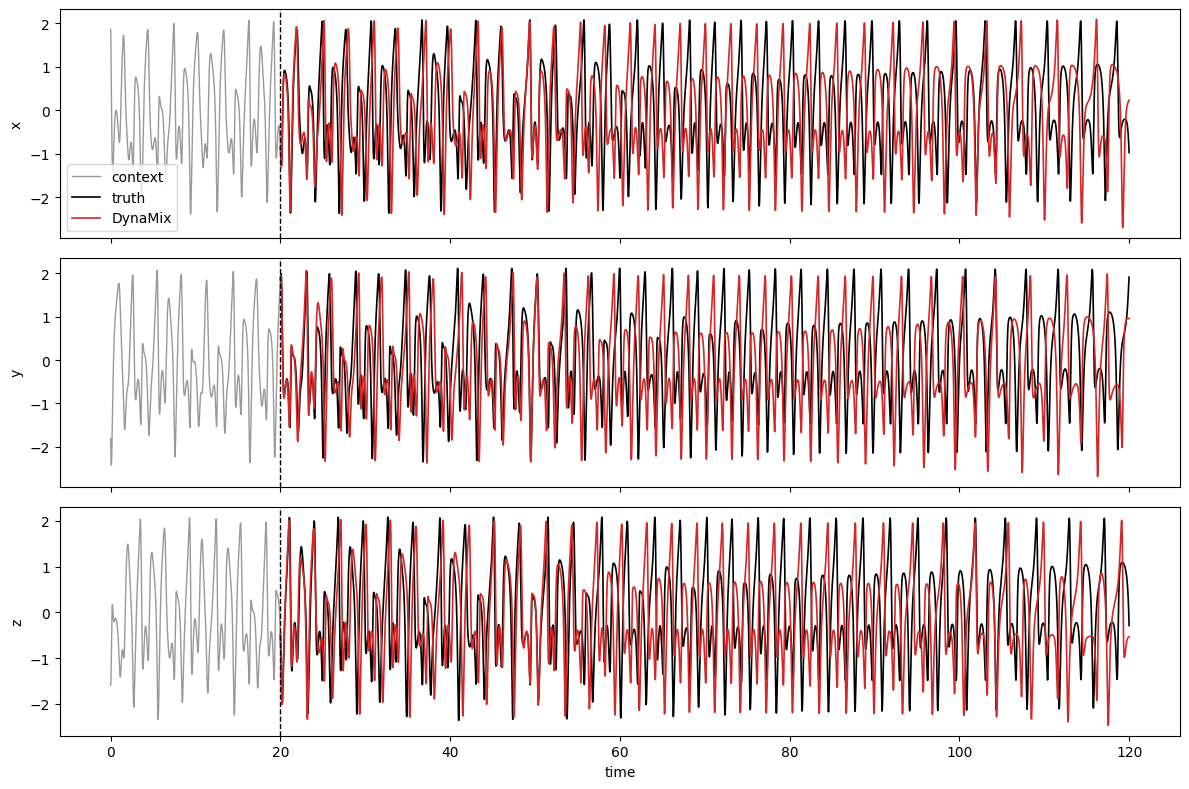

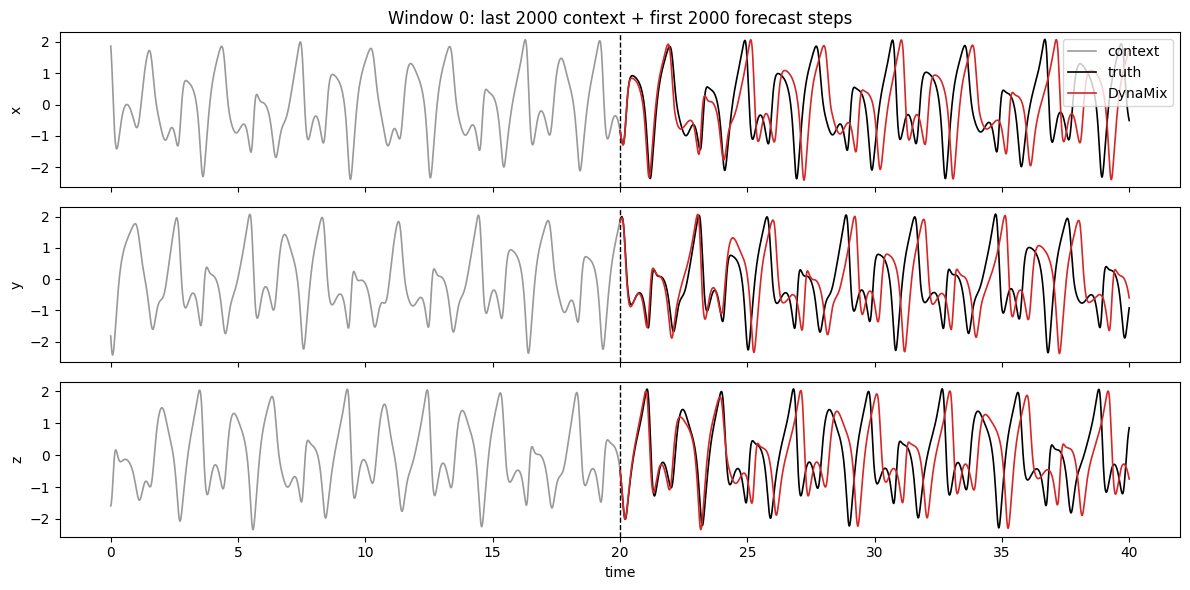

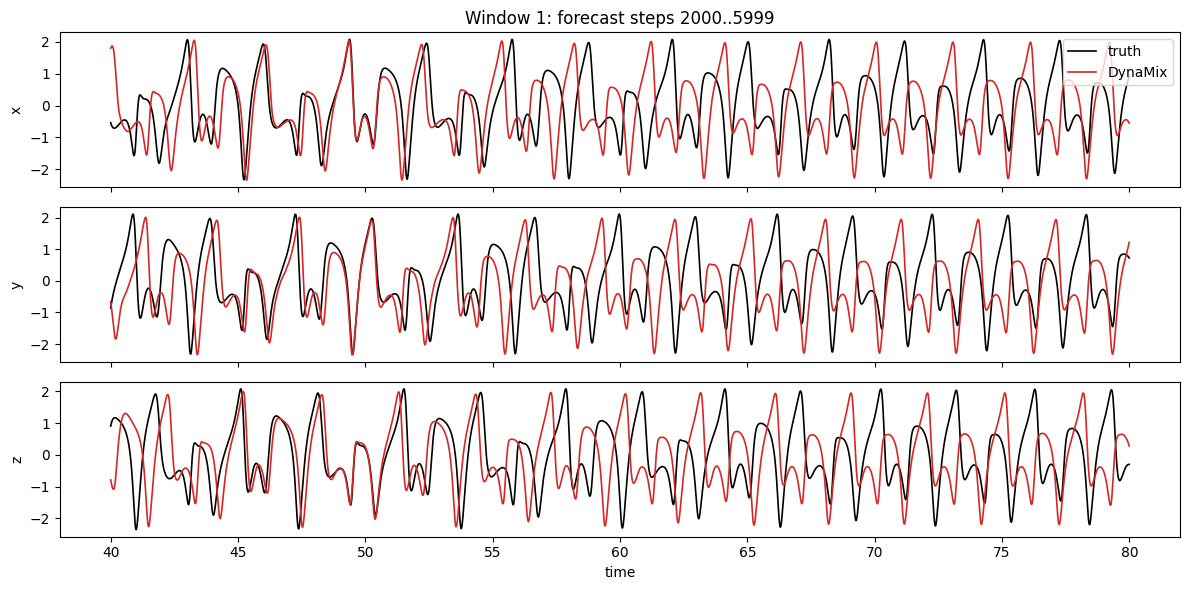

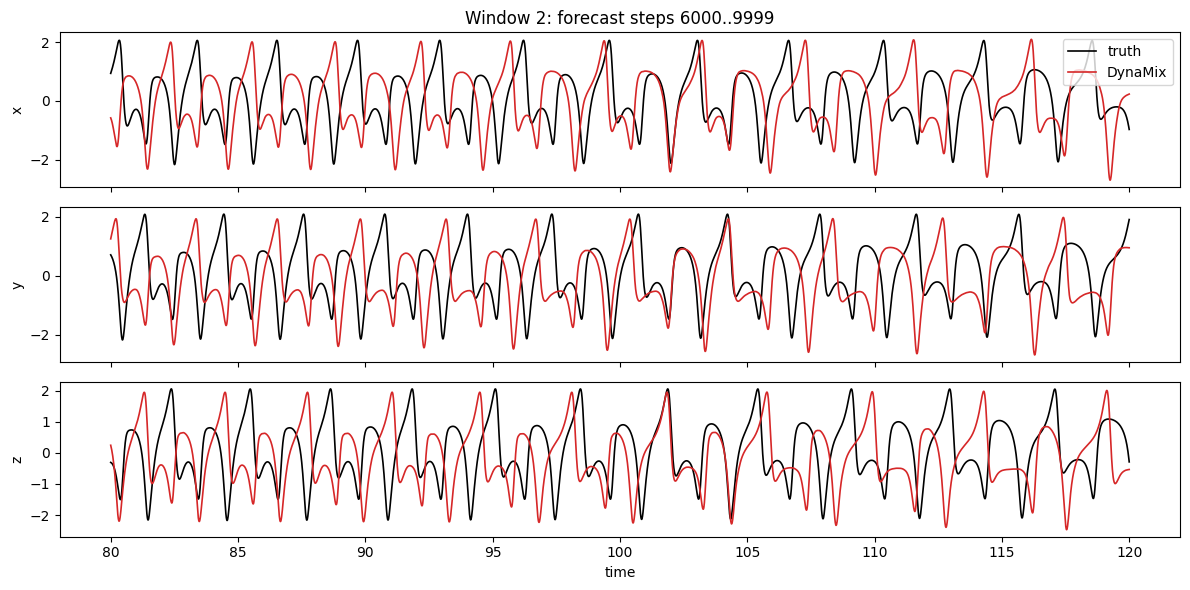

In [14]:
traj_id = 0
pred = result["pred"][:, traj_id, :]
truth = result["truth"][:, traj_id, :]
context = result["context"][:, traj_id, :]

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
target_t = np.arange(context_steps, context_steps + forecast_steps) * dt
context_t = np.arange(context_steps) * dt

for dim, ax in enumerate(axes):
    ax.plot(
        context_t,
        context[:, dim],
        color="0.6",
        lw=1.0,
        label="context" if dim == 0 else None,
    )
    ax.plot(
        target_t,
        truth[:, dim],
        color="black",
        lw=1.2,
        label="truth" if dim == 0 else None,
    )
    ax.plot(
        target_t,
        pred[:, dim],
        color="#d62728",
        lw=1.2,
        label="DynaMix" if dim == 0 else None,
    )
    ax.axvline(context_steps * dt, color="black", ls="--", lw=1.0)
    ax.set_ylabel(["x", "y", "z"][dim])
axes[0].legend()
axes[-1].set_xlabel("time")
plt.tight_layout()

# Split dimension plots into three large windows covering all 12000 steps:
# 1) full 2000-step context + first 2000 forecast steps,
# 2) next 4000 forecast steps,
# 3) final 4000 forecast steps.
chunk_steps = 4000
context_tail_steps = min(2000, context_steps)
max_chunk_plots = 3

chunk_specs = [
    (-context_tail_steps, min(chunk_steps - context_tail_steps, forecast_steps))
]
for start in range(chunk_specs[0][1], forecast_steps, chunk_steps):
    chunk_specs.append((start, min(start + chunk_steps, forecast_steps)))
if max_chunk_plots is not None:
    chunk_specs = chunk_specs[:max_chunk_plots]

for plot_idx, (start, end) in enumerate(chunk_specs):
    fig, axes = plt.subplots(3, 1, figsize=(12, 6), sharex=True)
    if start < 0:
        ctx_idx = np.arange(context_steps + start, context_steps)
        pred_idx = np.arange(0, end)
        window_t = np.concatenate([ctx_idx, context_steps + pred_idx]) * dt
        context_window = context[ctx_idx, :]
        truth_window = truth[pred_idx, :]
        pred_window = pred[pred_idx, :]
        title = f"Window {plot_idx}: last {len(ctx_idx)} context + first {len(pred_idx)} forecast steps"
    else:
        pred_idx = np.arange(start, end)
        window_t = (context_steps + pred_idx) * dt
        context_window = None
        truth_window = truth[pred_idx, :]
        pred_window = pred[pred_idx, :]
        title = f"Window {plot_idx}: forecast steps {start}..{end - 1}"

    for dim, ax in enumerate(axes):
        if context_window is not None:
            ax.plot(
                window_t[: len(context_window)],
                context_window[:, dim],
                color="0.6",
                lw=1.2,
                label="context" if dim == 0 else None,
            )
            ax.axvline(context_steps * dt, color="black", ls="--", lw=1.0)
            target_t_window = window_t[len(context_window) :]
        else:
            target_t_window = window_t
        ax.plot(
            target_t_window,
            truth_window[:, dim],
            color="black",
            lw=1.2,
            label="truth" if dim == 0 else None,
        )
        ax.plot(
            target_t_window,
            pred_window[:, dim],
            color="#d62728",
            lw=1.2,
            label="DynaMix" if dim == 0 else None,
        )
        ax.set_ylabel(["x", "y", "z"][dim])
    axes[0].set_title(title)
    axes[0].legend(loc="upper right")
    axes[-1].set_xlabel("time")
    plt.tight_layout()

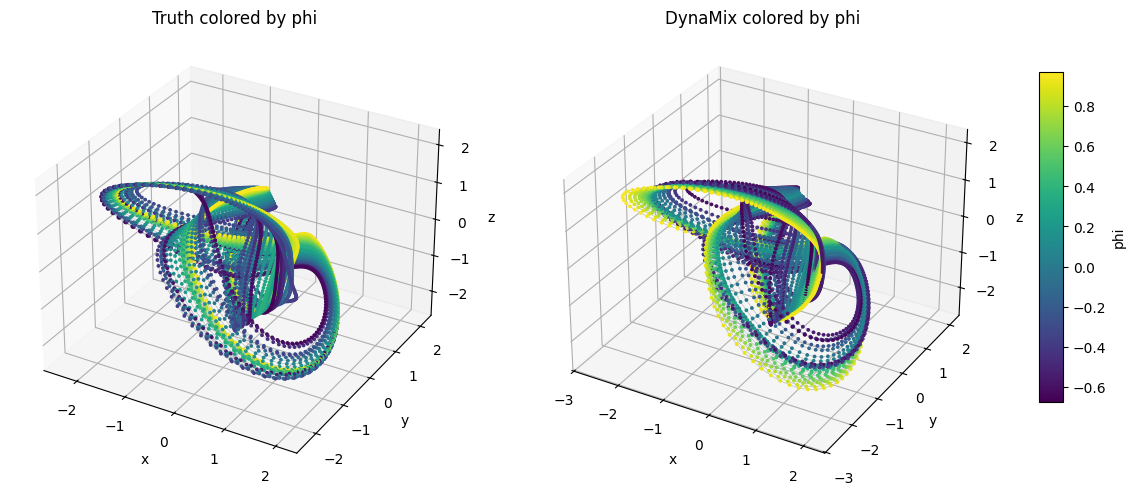

In [15]:
phi_target = test_phi[context_steps : context_steps + forecast_steps, traj_id, 0]

fig = plt.figure(figsize=(12, 5))
ax_truth = fig.add_subplot(121, projection="3d")
ax_pred = fig.add_subplot(122, projection="3d")

for ax, arr, title in [
    (ax_truth, truth, "Truth colored by phi"),
    (ax_pred, pred, "DynaMix colored by phi"),
]:
    ax.plot(arr[:, 0], arr[:, 1], arr[:, 2], color="0.75", lw=0.5)
    sc = ax.scatter(
        arr[:, 0],
        arr[:, 1],
        arr[:, 2],
        c=phi_target,
        cmap="viridis",
        s=3,
        depthshade=False,
    )
    ax.set_title(title)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_zlabel("z")

fig.subplots_adjust(left=0.02, right=0.86, bottom=0.02, top=0.92, wspace=0.10)
cax = fig.add_axes([0.89, 0.18, 0.02, 0.66])
fig.colorbar(sc, cax=cax, label="phi")